# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Ford Car Price Dataset](https://www.kaggle.com/datasets/adhurimquku/ford-car-price-prediction)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('ford.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


## last Five row

In [4]:
df.tail()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
17961,B-MAX,2017,8999,Manual,16700,Petrol,150,47.1,1.4
17962,B-MAX,2014,7499,Manual,40700,Petrol,30,57.7,1.0
17963,Focus,2015,9999,Manual,7010,Diesel,20,67.3,1.6
17964,KA,2018,8299,Manual,5007,Petrol,145,57.7,1.2
17965,Focus,2015,8299,Manual,5007,Petrol,22,57.7,1.0


## Shape of our dataset

In [5]:
df.shape

(17966, 9)

## List out all columns

In [6]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

model            object
year              int64
price             int64
transmission     object
mileage           int64
fuelType         object
tax               int64
mpg             float64
engineSize      float64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  object 
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  object 
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  object 
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 1.2+ MB


## Check Null Value

In [9]:
df.isnull().sum()

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(154)

## Summary

In [11]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

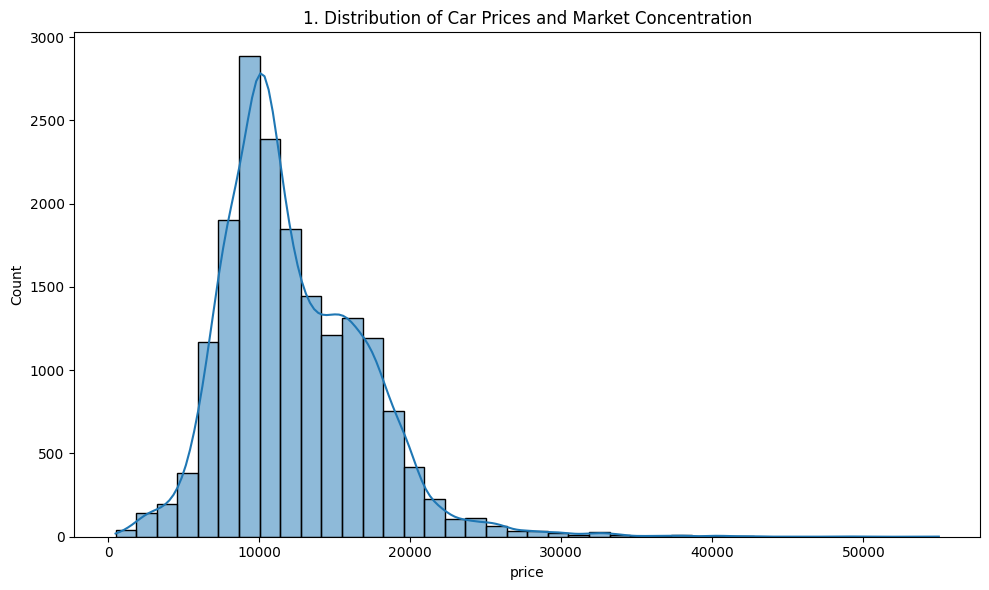

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='price', kde=True, bins=40)
plt.title(f'{plot_no}. Distribution of Car Prices and Market Concentration')
show_fig()
plot_no += 1

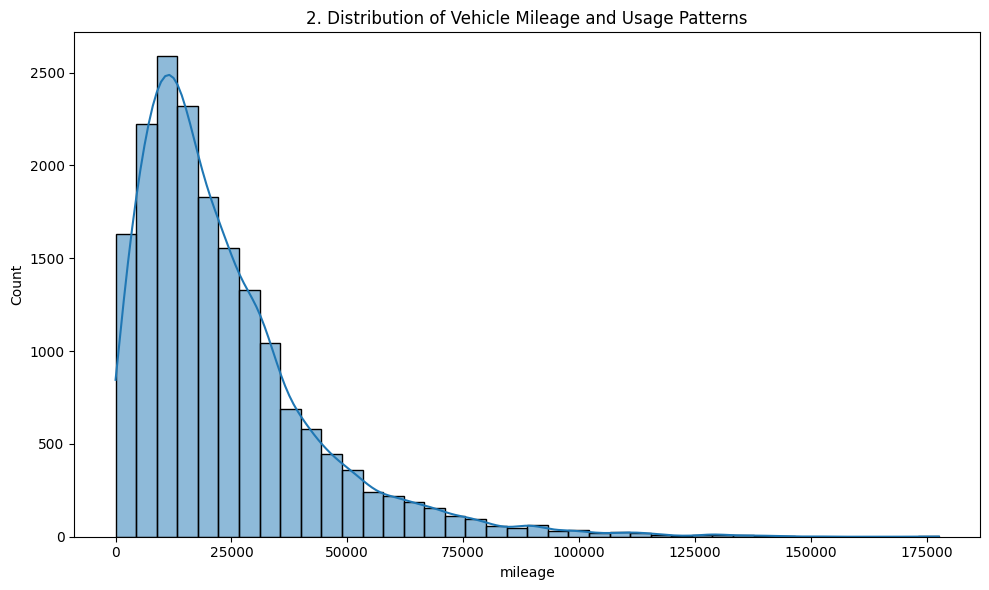

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='mileage', kde=True, bins=40)
plt.title(f'{plot_no}. Distribution of Vehicle Mileage and Usage Patterns')
show_fig()
plot_no += 1

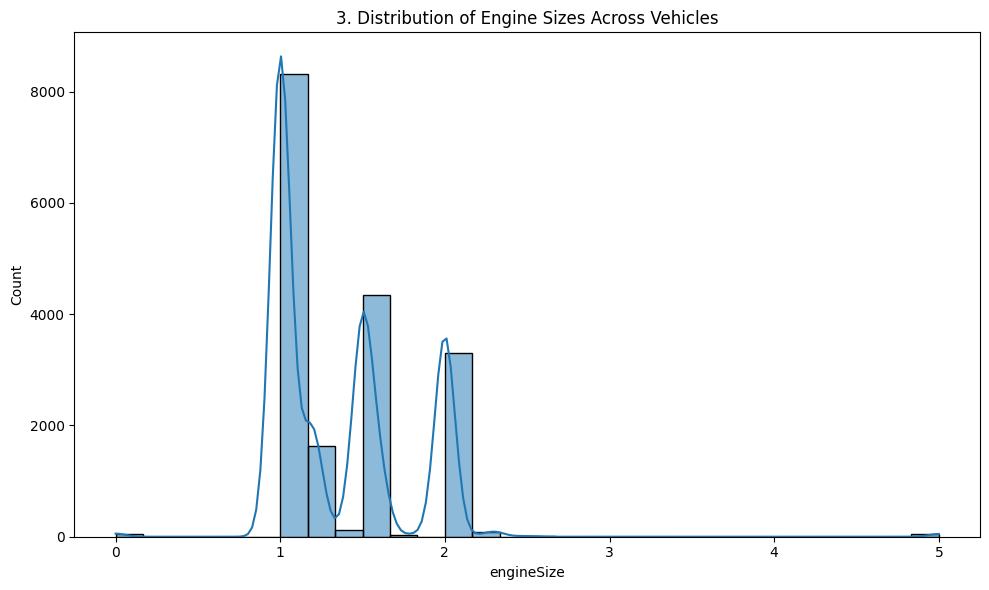

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='engineSize', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Engine Sizes Across Vehicles')
show_fig()
plot_no += 1

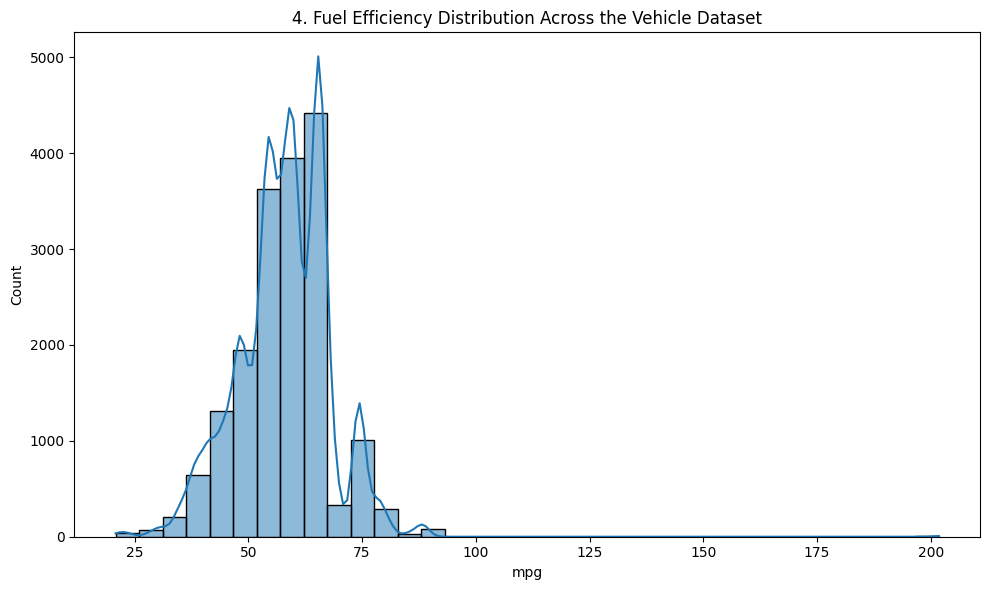

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='mpg', kde=True, bins=35)
plt.title(f'{plot_no}. Fuel Efficiency Distribution Across the Vehicle Dataset')
show_fig()
plot_no += 1

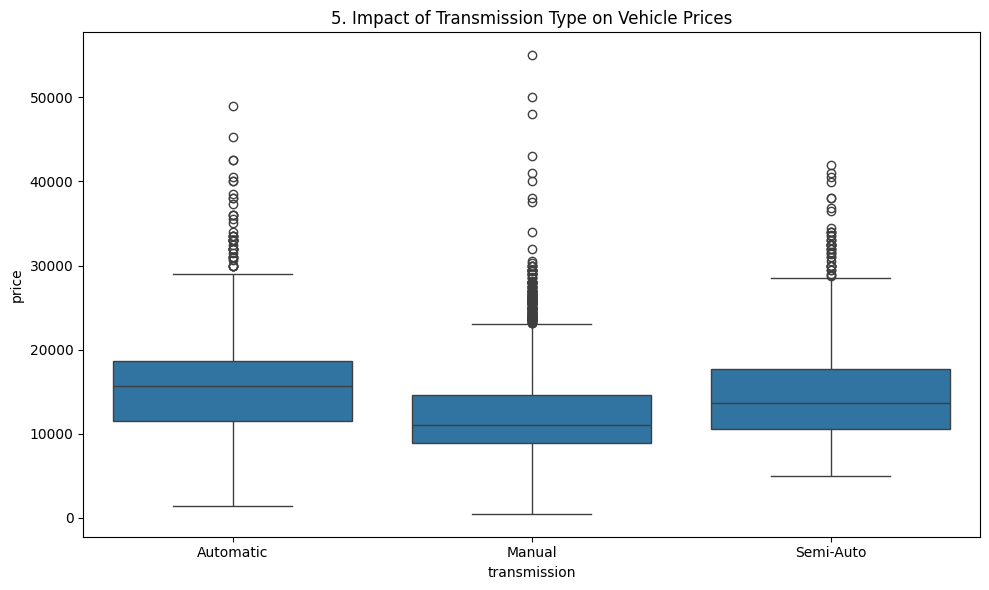

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='transmission', y='price')
plt.title(f'{plot_no}. Impact of Transmission Type on Vehicle Prices')
show_fig()
plot_no += 1

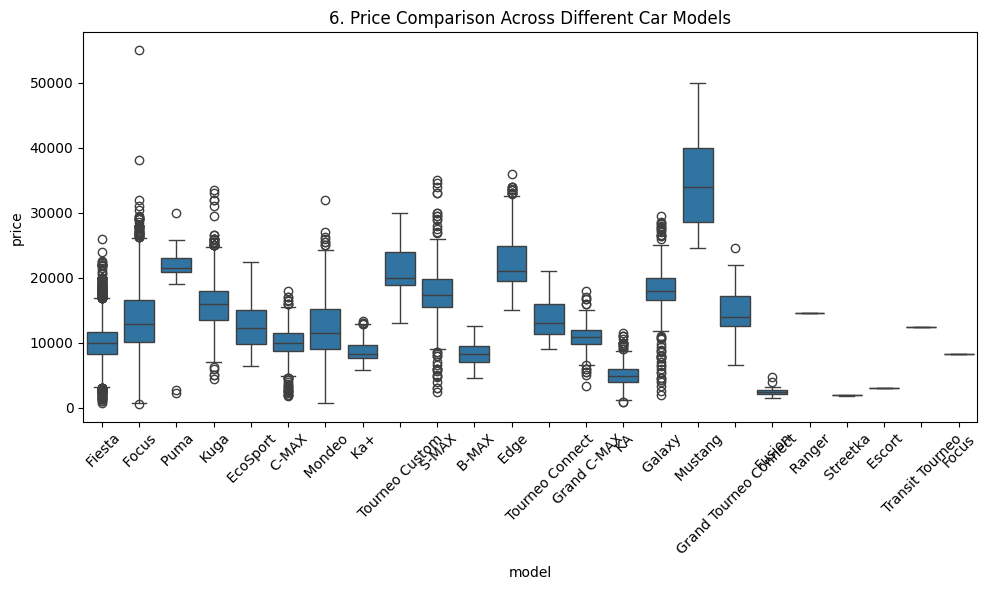

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='model', y='price')
plt.title(f'{plot_no}. Price Comparison Across Different Car Models')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

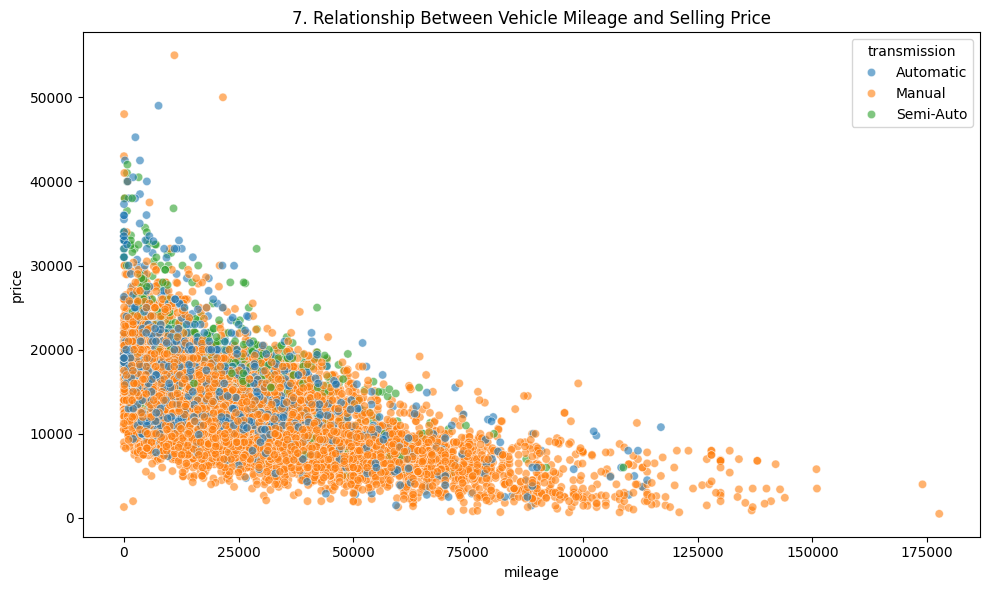

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='mileage', y='price', hue='transmission', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Vehicle Mileage and Selling Price')
show_fig()
plot_no += 1

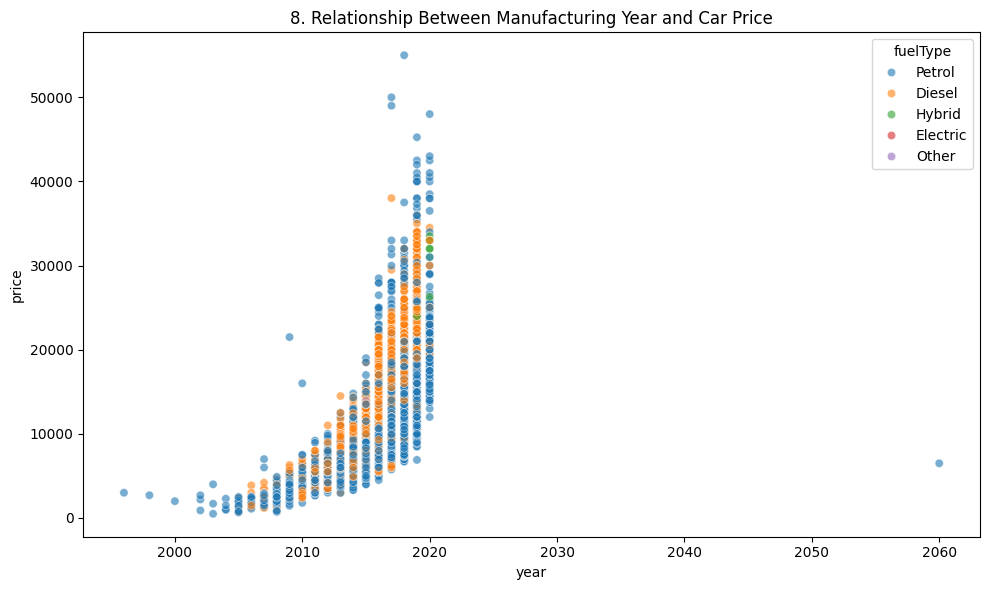

In [20]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='year', y='price', hue='fuelType', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Manufacturing Year and Car Price')
show_fig()
plot_no += 1

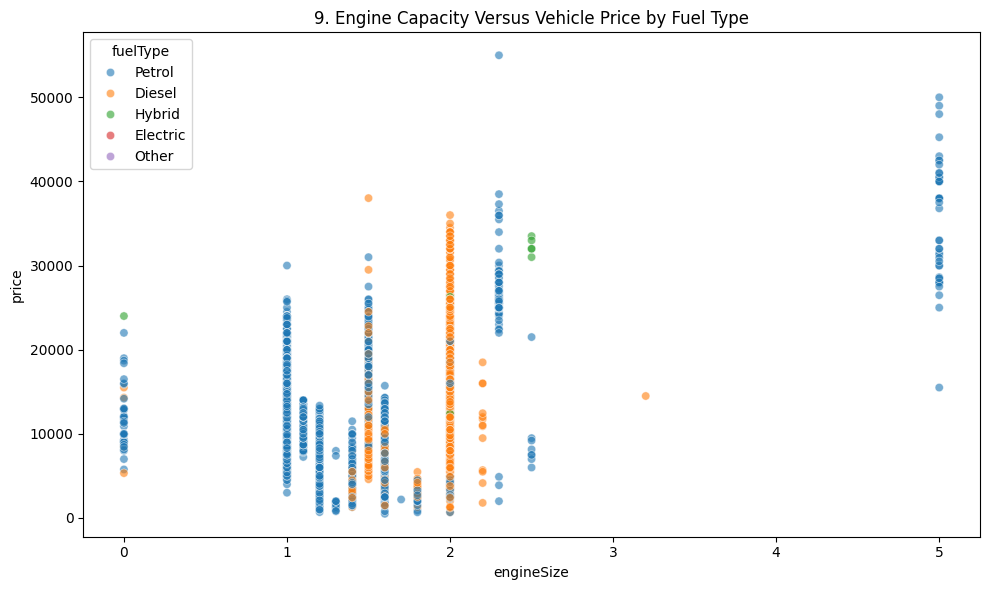

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='engineSize', y='price', hue='fuelType', alpha=0.6)
plt.title(f'{plot_no}. Engine Capacity Versus Vehicle Price by Fuel Type')
show_fig()
plot_no += 1

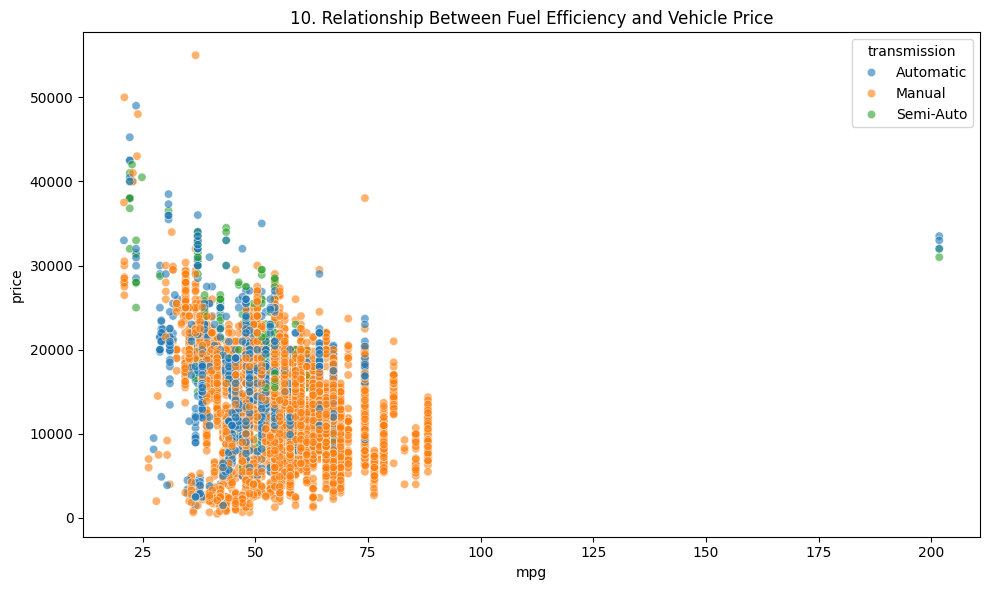

In [22]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='mpg', y='price', hue='transmission', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Fuel Efficiency and Vehicle Price')
show_fig()
plot_no += 1

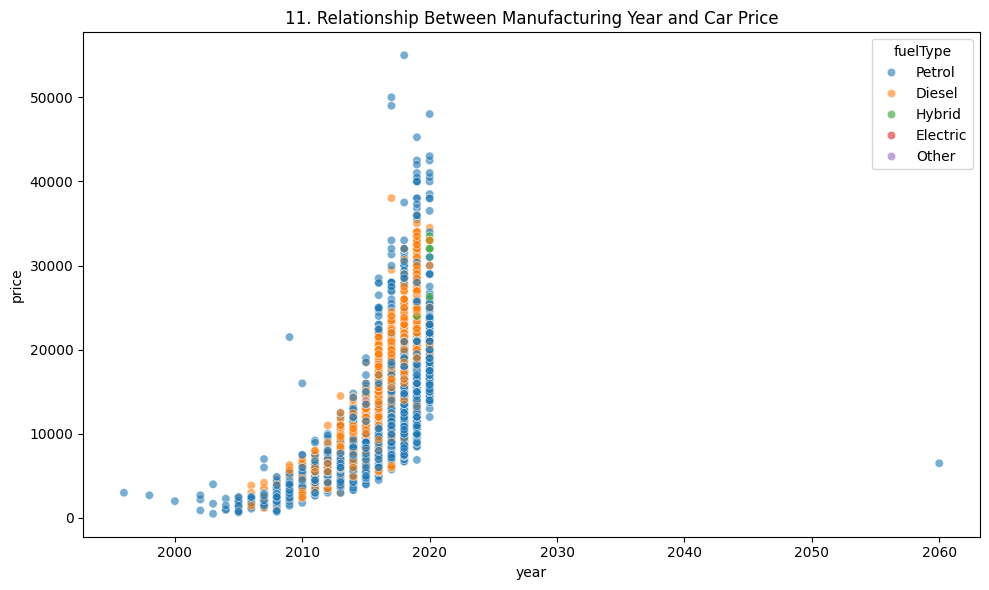

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='year', y='price', hue='fuelType', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Manufacturing Year and Car Price')
show_fig()
plot_no += 1

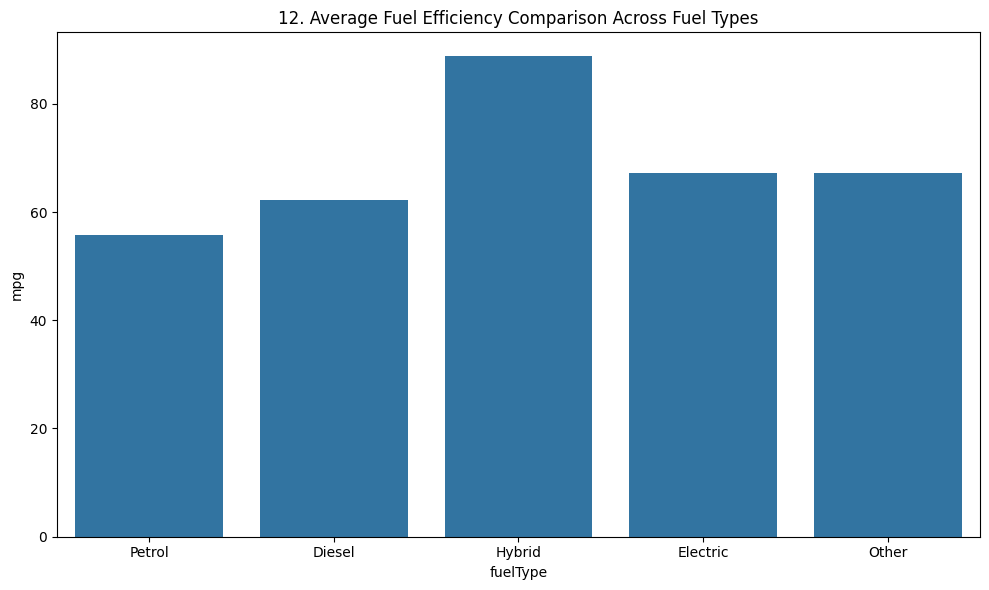

In [24]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='fuelType', y='mpg', errorbar=None)
plt.title(f'{plot_no}. Average Fuel Efficiency Comparison Across Fuel Types')
show_fig()
plot_no += 1

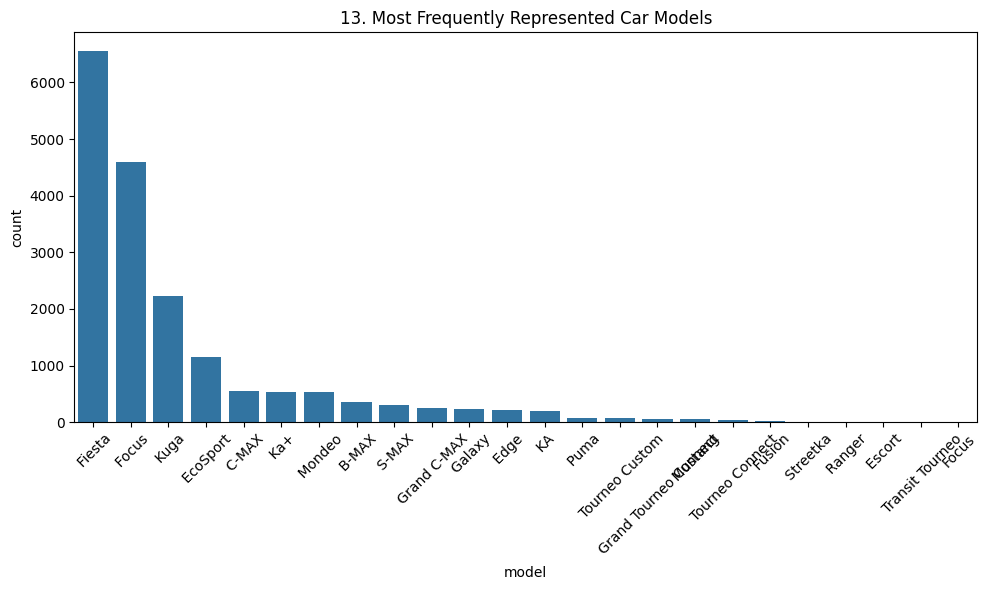

In [25]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='model', order=df['model'].value_counts().index)
plt.title(f'{plot_no}. Most Frequently Represented Car Models')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

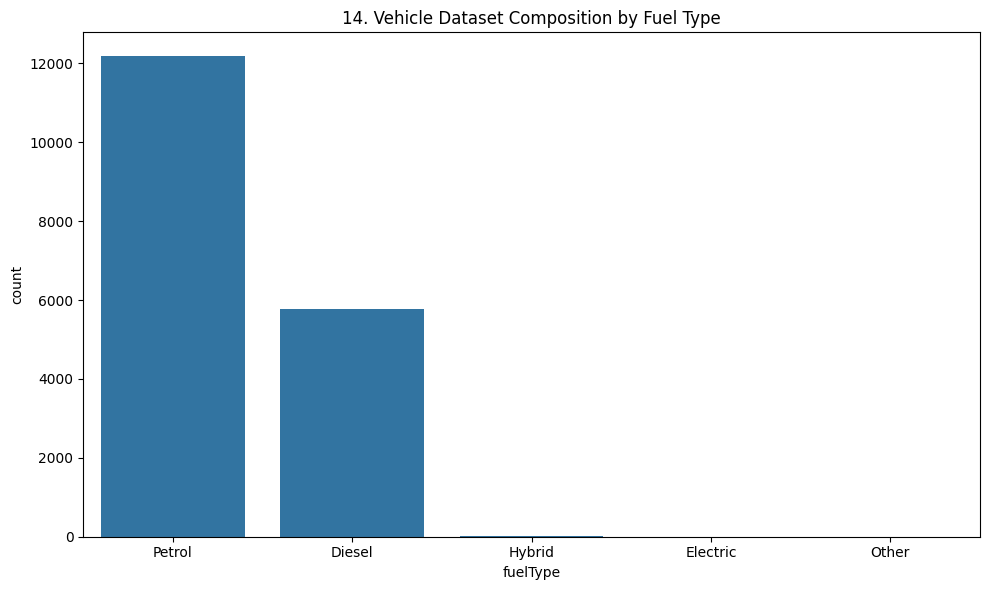

In [26]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='fuelType', order=df['fuelType'].value_counts().index)
plt.title(f'{plot_no}. Vehicle Dataset Composition by Fuel Type')
show_fig()
plot_no += 1

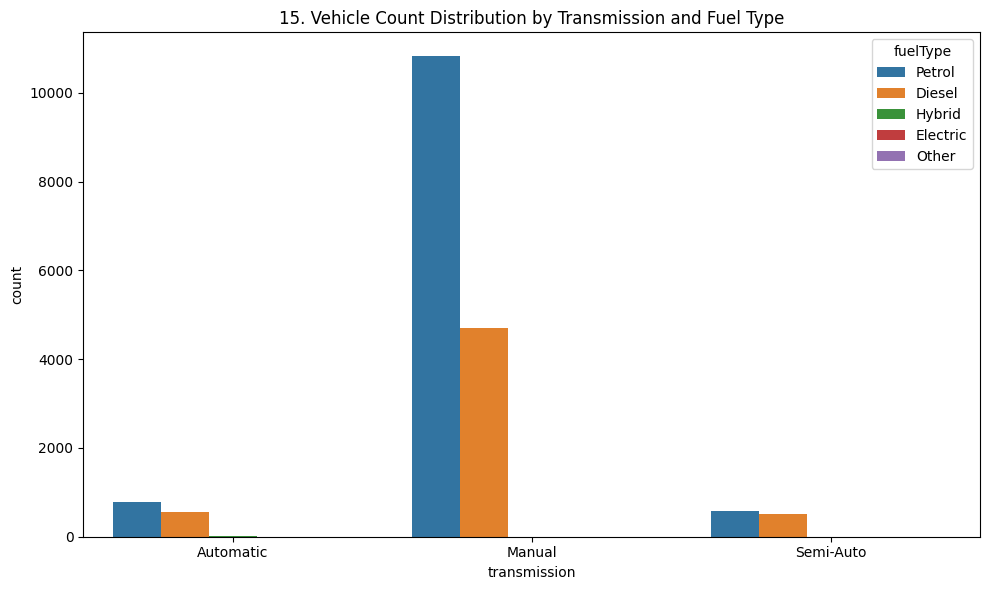

In [27]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='transmission', hue='fuelType')
plt.title(f'{plot_no}. Vehicle Count Distribution by Transmission and Fuel Type')
show_fig()
plot_no += 1

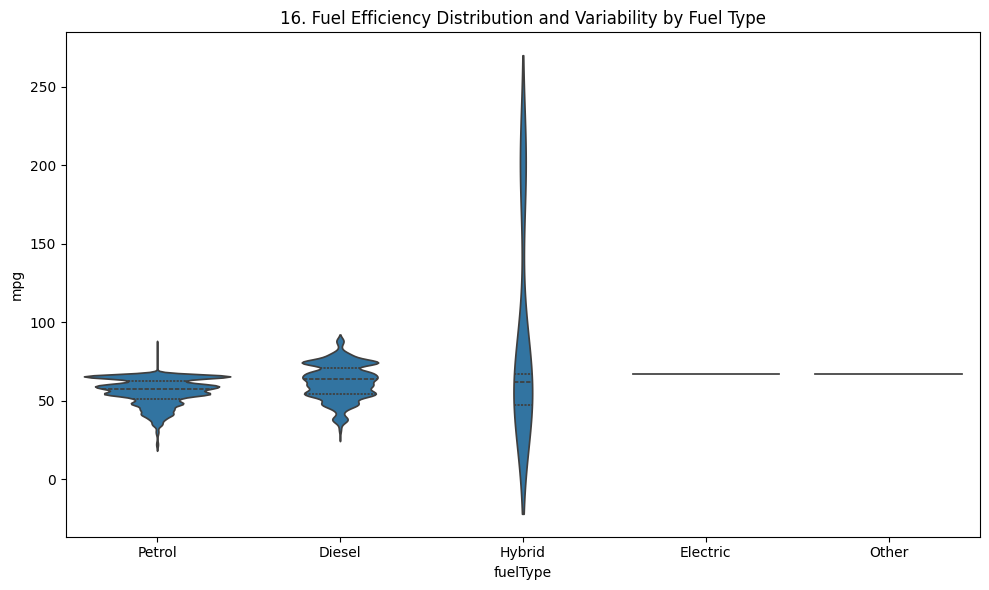

In [28]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='fuelType', y='mpg', inner='quartile')
plt.title(f'{plot_no}. Fuel Efficiency Distribution and Variability by Fuel Type')
show_fig()
plot_no += 1

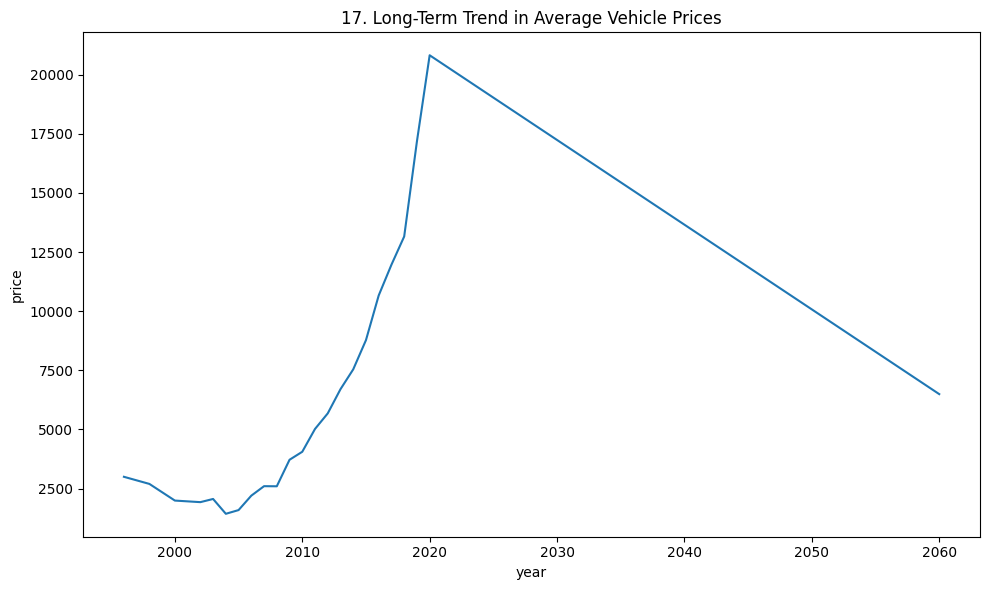

In [29]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='year', y='price', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Long-Term Trend in Average Vehicle Prices')
show_fig()
plot_no += 1

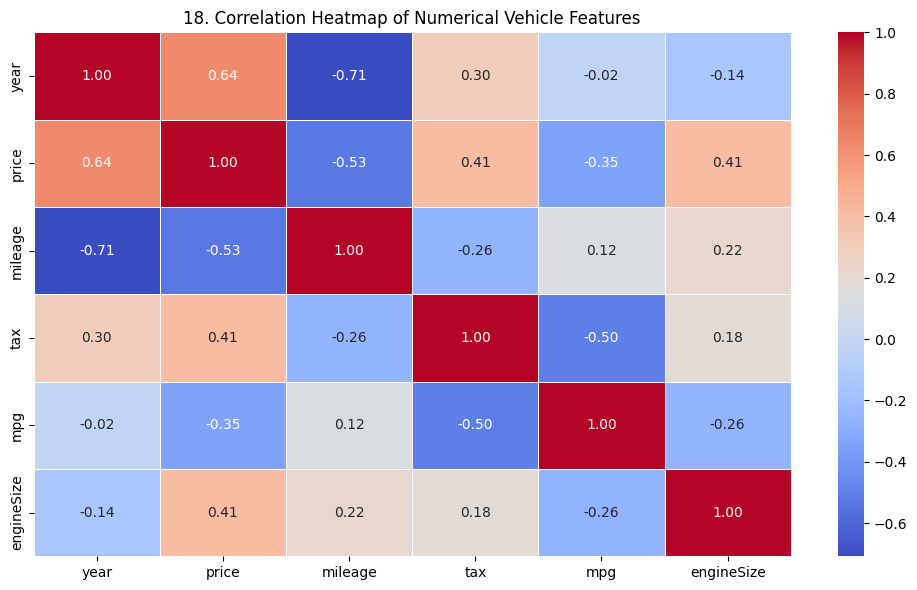

In [30]:
corr = df.select_dtypes(include='number').corr()
fig = plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Vehicle Features')
show_fig()
plot_no += 1

# Model Training

## Copy dataset

In [31]:
data = df.copy()

## Remove missing target values

In [32]:
data = data.dropna(subset=['price'])

## Separate features and target

In [33]:
X = data.drop(columns=['price'])
y = data['price']

## Identify categorical columns

In [34]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

## Handle categorical and numerical missing values

In [35]:
for col in cat_cols:
    X[col] = X[col].fillna('Unknown').astype(str)

num_cols = X.select_dtypes(include=np.number).columns.tolist()
X[num_cols] = X[num_cols].fillna(X[num_cols].median())

## Split dataset

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train advanced CatBoost model

In [37]:
model = CatBoostRegressor(
    iterations=1200,
    learning_rate=0.04,
    depth=8,
    loss_function='RMSE',
    verbose=0,
    random_seed=42
)

model.fit(X_train, y_train, cat_features=cat_cols)

CatBoostRegressor(depth=8, iterations=1200, learning_rate=0.04, loss_function='RMSE', random_seed=42, verbose=0)

## Make predictions

In [38]:
y_pred = model.predict(X_test)

## Evaluate model

In [39]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("R2 Score:", round(r2, 4))
print("Accuracy:", round(r2 * 100, 2), "% (R2-based score, not classification accuracy)")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

R2 Score: 0.9429
Accuracy: 94.29 % (R2-based score, not classification accuracy)
MAE: 784.85
RMSE: 1131.69


## Actual vs Predicted visualization

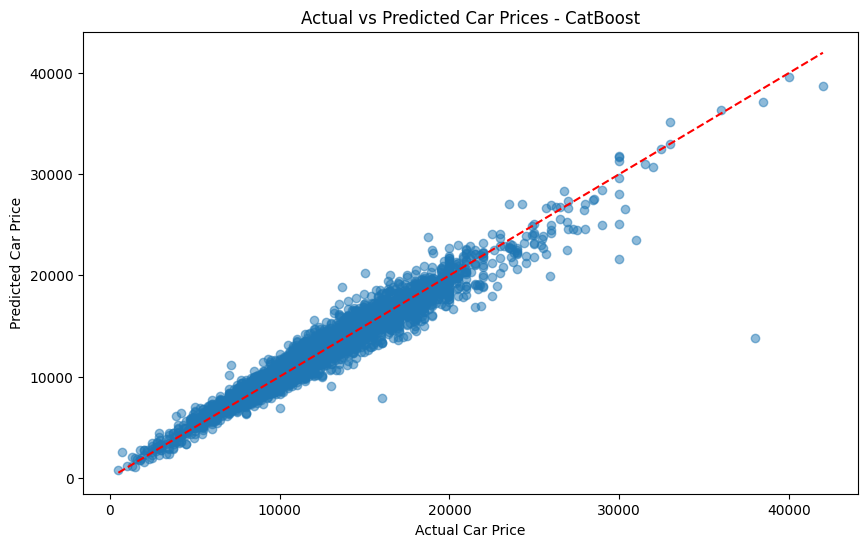

In [40]:
fig = plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices - CatBoost")
plt.show()